# Agents — Building a Goal-Based Agent with an LLM

Laboratory solution for `Agents.pdf`.

This notebook works through the three tasks of the lab in order: first understand the
warehouse navigation problem on paper, then design the agent before a single line of
code is written, then use a Large Language Model to generate the implementation, test
it, find what is wrong with it, improve the prompt, and generate a corrected version.

**How to read this notebook.** Every section opens with the question, states the
answer, and then shows the code that produces the evidence. Every number in the
tables below was produced by running the cells in this notebook — nothing is quoted
from the lab document.

**The warehouse (from the lab):**

```text
#####################
#S....#............G#
#.##....##########..#
#....##.............#
#.######.###.#.###..#
#........#..........#
#####################
```

`S` is the start, `G` is the goal, `#` is a shelving unit that cannot be crossed, and
`.` is free space. The vehicle moves Up, Down, Left or Right; one move changes its
position by one grid square.

**A note on the LLM used here.** The "LLM" in this lab is the assistant that wrote
this notebook. The draft in Task 3 was produced from the Task 3 prompt by that model,
written from the design without being executed first — exactly the way a student
receives code from a chat assistant. The failures reported in Task 3 are therefore
real failures of a first draft, not staged ones.

## Task 1: Understand the problem

The lab asks five questions before any software is written. Here they are, with the
answers, and with the evidence that the answers are right.

### Q1. What is the environment?

The environment is the warehouse floor: a finite, static, two-dimensional grid of
21 columns by 7 rows. "Static" means the shelving units never move, so the map is a
**constant** of the problem and not part of the state. "Finite" means the vehicle can
only ever be in one of the 147 cells, of which 66 are free.

Three properties of the environment decide the whole design:

- **Fully observable.** The vehicle knows exactly which cell it occupies and it can
  read the whole map. There is no sensor noise and no partial observation, so the
  agent's internal state is a complete description of the world.
- **Deterministic.** Every action has exactly one outcome, fixed by the map. Moving
  Right from cell $(r, c)$ always leads to $(r, c+1)$ if that cell is free. There is
  no randomness and no chance transition to model.
- **Discrete.** The state space is finite and countable, so a search over it
  terminates.

The vehicle carries no package, has no fuel, has no orientation and opens no doors.
The only thing that changes from moment to moment is the position.

### Q2. What is the goal of the agent?

The goal is to get the vehicle from `S` to `G` — and, in the words of the lab, to do
it *collision-free*, that is, without ever occupying a shelving unit.

Formally the goal is a set of states, $G = \{(1, 19)\}$, and the goal test is
`state in G`. Because $G$ holds a single cell, this is an equality test.

There is a second, quieter requirement. The lab says the vehicle "must determine a
collision-free path", which implies that *the path* matters and not merely the
arrival. The natural reading — and the one used throughout this notebook — is that
the agent should return a **shortest** collision-free path: every move costs the
same (one step), so "shortest" means "fewest moves".

This reading is what makes the answer checkable. A path is correct if and only if its
length equals the length of the shortest path, and the shortest path can be computed
by an independent breadth-first search. Without such an oracle, "the program printed
a path" is not a statement that can be verified.

### Q3. What actions are available to the agent?

Four actions: `Up`, `Down`, `Left`, `Right`. Each changes the position by exactly one
cell in a cardinal direction, and each costs 1.

An action is **applicable** only when the resulting cell is a free cell inside the
grid. A move into a shelving unit is not an expensive move — it is not a move at all,
and a correct agent never generates it. The action set available at a given state is
therefore the subset of the four actions whose successor cell is free; standing next
to the top wall, `Up` simply is not available.

Because there are exactly four actions and each has one successor, the state space is
a graph with at most four edges per node — the classic grid-search situation.

### Q4. What information must the agent maintain?

The agent must maintain four things:

1. **Its current position.** This is the whole of its internal state: because the
   map is static and the vehicle carries nothing, the position determines the world
   completely.
2. **The goal.** The cell `G` it is trying to reach. The goal lives *in the agent*,
   not in the environment — that is exactly what makes the agent goal-based rather
   than reflex.
3. **The plan.** The sequence of actions still to be executed. A goal-based agent
   separates *deliberation* (working out the plan) from *action* (executing it).
4. **The search bookkeeping.** The frontier of states that have been discovered but
   not yet expanded, the best cost found so far for each state, and the predecessor
   of each state so that the plan can be reconstructed at the end.

One thing that looks like a state variable is in fact a **constant**: the set of
shelving cells. It never changes, so it is part of the environment and is read, not
remembered.

### Q5. Why is this a goal-based agent rather than a simple reflex agent?

A **reflex agent** maps each percept directly to an action. It reacts to what it
sees now, with no representation of what it is trying to achieve and no memory of
where it has been. "Move right if the cell to the right is free, otherwise move
down" is a perfectly well-defined reflex policy.

A **goal-based agent** holds an explicit objective and uses it to select actions that
move it towards that objective. It keeps the goal in its internal state and
*deliberates*: it constructs a sequence of actions that is expected to reach the
goal, and only then acts.

The difference is not academic — it is visible on this very map. The reflex policy in
the next cell is given exactly the same information as the goal-based agent (the
whole map and its exact position), and it still fails, because no rule of the form
"react to the cell you are in" can know that the corridor it is standing in ends in a
dead end. The goal-based agent succeeds because it can *look ahead*: it searches the
state space for a path to `G` and then follows that path.

In [1]:
WAREHOUSE = [
    "#####################",
    "#S....#............G#",
    "#.##....##########..#",
    "#....##.............#",
    "#.######.###.#.###..#",
    "#........#..........#",
    "#####################",
]

MOVES = {"Up": (-1, 0), "Down": (1, 0), "Left": (0, -1), "Right": (0, 1)}


def manhattan(a, b):
    """Manhattan distance between two cells - the straight-line grid distance."""
    return abs(a[0] - b[0]) + abs(a[1] - b[1])


def parse_grid(grid):
    """Turn the ASCII warehouse into the four things the search needs.

    Returns (start, goal, blocked, free):
      start   - the cell marked 'S'
      goal    - the cell marked 'G'
      blocked - the set of shelving units
      free    - every cell that is not a shelving unit, so membership also
                enforces the boundary of the grid
    """
    start = goal = None
    blocked = set()
    for r, row in enumerate(grid):
        for c, ch in enumerate(row):
            if ch == "S":
                start = (r, c)
            elif ch == "G":
                goal = (r, c)
            elif ch == "#":
                blocked.add((r, c))
    free = {(r, c) for r in range(len(grid)) for c in range(len(grid[0]))} - blocked
    return start, goal, blocked, free


START, GOAL, BLOCKED, FREE = parse_grid(WAREHOUSE)

print("warehouse size           :", len(WAREHOUSE), "rows x", len(WAREHOUSE[0]), "columns")
print("cells in the grid        :", len(WAREHOUSE) * len(WAREHOUSE[0]))
print("free cells (state space) :", len(FREE))
print("shelving units           :", len(BLOCKED))
print("start cell (S)           :", START)
print("goal cell (G)            :", GOAL)
print("Manhattan distance S->G  :", manhattan(START, GOAL))
print("border is a solid wall   :",
      all(ch == "#" for ch in WAREHOUSE[0]) and all(ch == "#" for ch in WAREHOUSE[-1]))

warehouse size           : 7 rows x 21 columns
cells in the grid        : 147
free cells (state space) : 66
shelving units           : 81
start cell (S)           : (1, 1)
goal cell (G)            : (1, 19)
Manhattan distance S->G  : 18
border is a solid wall   : True


In [2]:
from collections import deque


def bfs_reference(grid):
    """Breadth-first reference search - the oracle used by the test suite.

    Every move costs 1, so the first time the goal is reached, the number of moves
    taken is the smallest possible. 'expanded' counts states that were removed
    from the frontier and had their successors generated.
    """
    start, goal, blocked, free = parse_grid(grid)
    frontier = deque([(start, 0)])
    parent = {start: None}
    visited = {start}
    expanded = 0

    while frontier:
        current, g = frontier.popleft()
        expanded += 1

        if current == goal:
            path = []
            node = current
            while node is not None:
                path.append(node)
                node = parent[node]
            return {"found": True, "path": path[::-1], "length": g, "expanded": expanded}

        for name, (dr, dc) in MOVES.items():
            nxt = (current[0] + dr, current[1] + dc)
            if nxt in free and nxt not in visited:
                visited.add(nxt)
                parent[nxt] = current
                frontier.append((nxt, g + 1))

    return {"found": False, "path": None, "length": None, "expanded": expanded}


# --- is the map itself well formed, and is the problem solvable? ---
widths = {len(row) for row in WAREHOUSE}
print("distinct row widths       :", widths, "->", "rectangular" if len(widths) == 1 else "RAGGED")
print("exactly one S             :", sum(row.count("S") for row in WAREHOUSE) == 1)
print("exactly one G             :", sum(row.count("G") for row in WAREHOUSE) == 1)
print("S and G are free cells    :", START in FREE and GOAL in FREE)

reference = bfs_reference(WAREHOUSE)
print()
print("the problem is solvable    :", reference["found"])
print("shortest path (BFS)       :", reference["length"], "moves")
print("states BFS expanded        :", reference["expanded"], "of", len(FREE), "free cells")
print("the shortest path is collision-free:",
      all(cell in FREE for cell in reference["path"]))
print()
print("the shortest path:")
path_cells = set(reference["path"])
for r, row in enumerate(WAREHOUSE):
    print("   " + "".join("*" if (r, c) in path_cells else ch for c, ch in enumerate(row)))

distinct row widths       : {21} -> rectangular
exactly one S             : True
exactly one G             : True
S and G are free cells    : True

the problem is solvable    : True
shortest path (BFS)       : 20 moves
states BFS expanded        : 59 of 66 free cells
the shortest path is collision-free: True

the shortest path:
   #####################
   #****.#*************#
   #.##****##########..#
   #....##.............#
   #.######.###.#.###..#
   #........#..........#
   #####################


In [3]:
# The reflex agent, for contrast with the goal-based agent.

def reflex_run(start, goal, free, max_steps=200):
    """A reflex policy: react to the cell you are in.

    'Try Right, else Down, else Up, else Left' is a complete and deterministic
    policy that uses the same information the goal-based agent uses.
    """
    position = start
    trace = [position]
    for _ in range(max_steps):
        if position == goal:
            return True, trace
        for name in ("Right", "Down", "Up", "Left"):
            dr, dc = MOVES[name]
            nxt = (position[0] + dr, position[1] + dc)
            if nxt in free:
                position = nxt
                trace.append(position)
                break
        else:
            return False, trace
    return False, trace


reached, trace = reflex_run(START, GOAL, FREE)
print("reflex agent reached the goal :", reached)
print("steps taken                   :", len(trace) - 1)
print("distinct cells visited        :", len(set(trace)))
print("final position                :", trace[-1])
print()
print("The reflex agent is not stuck in one place - it keeps moving - but it")
print("cycles inside the bottom-right region of the warehouse and never")
print("reaches G. Its policy contains no notion of the goal, so nothing in it")
print("can tell it to leave that region.")
print()
print("the cells the reflex agent visited:")
visited = set(trace)
for r, row in enumerate(WAREHOUSE):
    print("   " + "".join("o" if (r, c) in visited else ch for c, ch in enumerate(row)))

reflex agent reached the goal : False
steps taken                   : 200
distinct cells visited        : 23
final position                : (5, 19)

The reflex agent is not stuck in one place - it keeps moving - but it
cycles inside the bottom-right region of the warehouse and never
reaches G. Its policy contains no notion of the goal, so nothing in it
can tell it to leave that region.

the cells the reflex agent visited:
   #####################
   #ooooo#............G#
   #.##.ooo##########..#
   #....##ooooooooooooo#
   #.######.###.#.###.o#
   #........#.........o#
   #####################


### Think about it: what if the warehouse becomes twice as large?

If the warehouse doubles in both dimensions, the number of cells **quadruples**: the
$7 \times 21$ map (147 cells, 66 free) becomes a $14 \times 42$ map (588 cells, of
which roughly half are free). Almost everything else follows from that one
number.

- **The state space grows quadratically.** If there are $N$ free cells then there
  are far more than $N$ distinct paths through them, so the search tree cannot be
  enumerated; the search has to be guided.
- **The frontier grows.** An uninformed search such as BFS must keep every state it
  has discovered but not yet expanded in memory at the same time. On a map of this
  density that is a large fraction of all the free cells, so **memory**, not time,
  becomes the binding constraint.
- **The blind strategy degrades first.** BFS must explore the whole reachable region
  before it can be certain it has found the shortest path, so its cost grows with
  the size of the warehouse. A heuristic search pays only for the states that look
  promising, and the quality of the heuristic - not the size of the map - decides
  how much of the map it has to look at.
- **The traps get deeper.** A larger map contains larger dead ends and longer
  detours, so a heuristic that cannot see walls (Manhattan distance) is drawn into
  more of them. The detour grows, the estimate gets worse, and the ratio of
  estimated cost to true cost grows with the map.
- **The best strategy may change.** The same code still works, but when memory
  rather than time is the limit, a depth-first search with a cost bound (IDA\*)
  becomes preferable to a best-first search that holds a large frontier.

These are predictions, and the "Think about it" section further down measures them.

## Task 2: Design the agent

The lab asks for the design to be made *before* the code is generated. Five
components have to be identified.

| Component | Specification |
|---|---|
| **Environment** | The warehouse: a static $7 \times 21$ grid of cells, fully observable and deterministic. It changes only when the vehicle acts on it. |
| **Current state** | The vehicle's cell `(row, column)`. The map is constant, so the position is a complete description of the world. |
| **Goal** | The cell `G` $= (1, 19)$, held by the agent as part of its internal state. |
| **Actions** | `Up`, `Down`, `Left`, `Right`; each applicable only if the resulting cell is free; each costs 1. |
| **Decision-making component** | The planner: a search over the state space (A\* with Manhattan distance) that turns the current state and the goal into a plan, i.e. a sequence of actions. |

Two design rules fall out of this table. They are worth stating explicitly, because
they are exactly the rules the generated code in Task 3 breaks.

- **The environment is read-only to the agent.** The agent perceives the map; it
  does not edit it. A planner that rewrites the map it was handed has destroyed its
  own input.
- **The planner and the executor are separate.** The planner computes a plan; the
  agent then executes it, one action at a time, checking each action against the
  environment. A plan that was never executed is a claim, not a result.

### The block diagram

```text
        ENVIRONMENT  (the warehouse)
        +--------------------------------+
        |  shelving units, free cells,   |
        |  start S, goal G                |
        +-----------------+--------------+
                          |
                          |  percept: the vehicle's cell
                          v
        +--------------------------------+
        |             AGENT              |
        |  +--------------------------+  |
        |  | internal state            |  |
        |  |   position                |  |
        |  |   goal                    |  |
        |  |   remaining plan          |  |
        |  +------------+-------------+  |
        |               |                |
        |  +------------v-------------+  |
        |  | decision component        |  |
        |  |   planner: A* over the    |  |
        |  |   state space             |  |
        |  |   goal + state -> plan    |  |
        |  +------------+-------------+  |
        |               |                |
        |  +------------v-------------+  |
        |  | actuator / execution      |  |
        |  |   carry out ONE action,   |  |
        |  |   if it is legal          |  |
        |  +------------+-------------+  |
        +-----------------+--------------+
                          |
                          |  action: Up | Down | Left | Right
                          +-----------------> back to the ENVIRONMENT
```

The loop is the whole point of the architecture: the environment produces a
percept, the agent deliberates and acts, and the action changes the environment,
which produces the next percept. The agent never acts without a goal, and never
reacts without a plan.

In [4]:
class Warehouse:
    """The environment of the warehouse navigation problem.

    Static, fully observable and deterministic. The agent perceives it; it never
    modifies it. All the knowledge the agent has about the world comes through
    this object.
    """

    ACTIONS = {"Up": (-1, 0), "Down": (1, 0), "Left": (0, -1), "Right": (0, 1)}

    def __init__(self, grid):
        self.grid = [row if isinstance(row, str) else "".join(row) for row in grid]
        self.rows = len(self.grid)
        self.cols = len(self.grid[0])
        self.start = None
        self.goal = None
        self.blocked = set()
        for r, row in enumerate(self.grid):
            for c, ch in enumerate(row):
                if ch == "S":
                    self.start = (r, c)
                elif ch == "G":
                    self.goal = (r, c)
                elif ch == "#":
                    self.blocked.add((r, c))
        self.free = {(r, c) for r in range(self.rows) for c in range(self.cols)} - self.blocked

    def successors(self, cell):
        """The applicable actions at `cell`, as (action name, next cell) pairs."""
        result = []
        for name, (dr, dc) in self.ACTIONS.items():
            nxt = (cell[0] + dr, cell[1] + dc)
            if nxt in self.free:
                result.append((name, nxt))
        return result

    def goal_test(self, cell):
        """Is the agent's goal satisfied in this cell?"""
        return cell == self.goal

    def render(self, position=None, path=None):
        """Return the map as text, optionally marking a path and the agent."""
        marked = set(path or [])
        lines = []
        for r, row in enumerate(self.grid):
            out = []
            for c, ch in enumerate(row):
                cell = (r, c)
                if cell in marked:
                    out.append("*")
                elif position is not None and cell == position:
                    out.append("@")
                else:
                    out.append(ch)
            lines.append("".join(out))
        return "\n".join(lines)


env = Warehouse(WAREHOUSE)
print("environment rows x cols :", env.rows, "x", env.cols)
print("start / goal            :", env.start, "/", env.goal)
print("free cells              :", len(env.free))
print()
print("the actions available at the start cell:", [name for name, _ in env.successors(env.start)])
print("the actions available next to the top wall (1, 5):",
      [name for name, _ in env.successors((1, 5))])
print()
print(env.render())

environment rows x cols : 7 x 21
start / goal            : (1, 1) / (1, 19)
free cells              : 66

the actions available at the start cell: ['Down', 'Right']
the actions available next to the top wall (1, 5): ['Down', 'Left']

#####################
#S....#............G#
#.##....##########..#
#....##.............#
#.######.###.#.###..#
#........#..........#
#####################


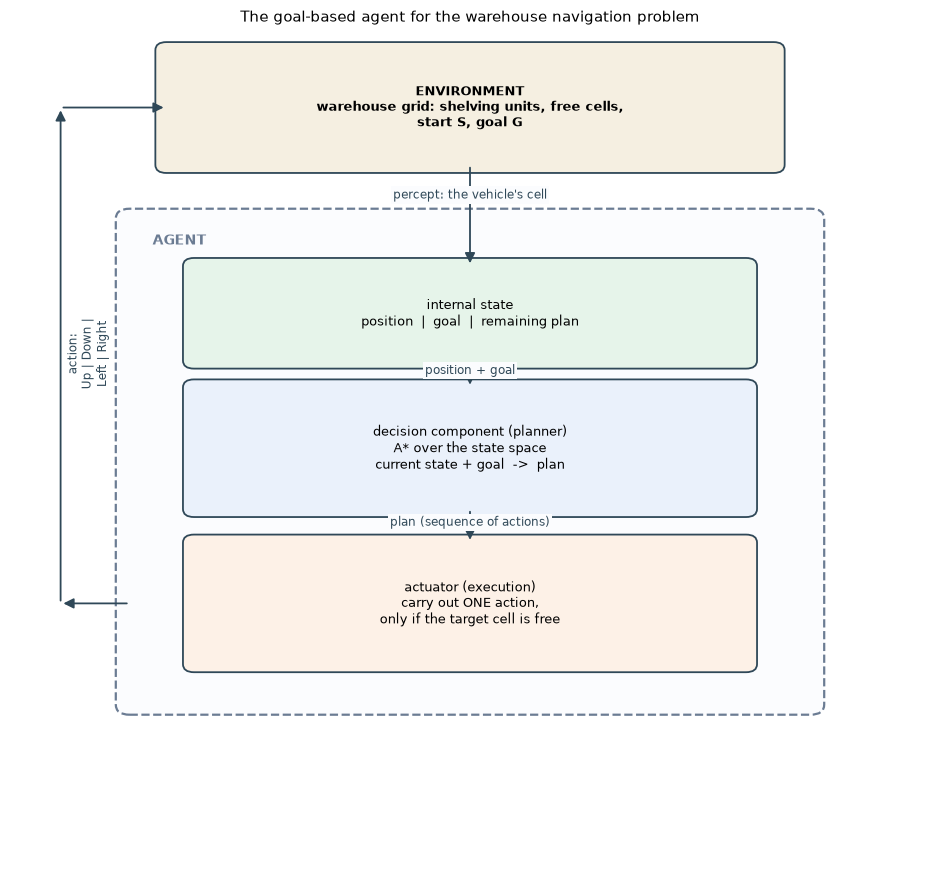

In [5]:
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch


def draw_architecture():
    """The block diagram of the goal-based agent, as a figure."""
    fig, ax = plt.subplots(figsize=(9.5, 9))
    ax.set_xlim(0, 10)
    ax.set_ylim(0, 12.6)
    ax.axis("off")

    def box(x, y, w, h, text, face="#eaf1fb", size=9, weight="normal"):
        ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.12",
                                    facecolor=face, edgecolor="#2f4858", linewidth=1.3))
        ax.text(x + w / 2, y + h / 2, text, ha="center", va="center",
                fontsize=size, weight=weight)

    def arrow(x1, y1, x2, y2, label=None, rad=0.0, dx=0.0, dy=0.0):
        ax.add_patch(FancyArrowPatch((x1, y1), (x2, y2), arrowstyle="-|>",
                                     mutation_scale=15, color="#2f4858", linewidth=1.3,
                                     connectionstyle="arc3,rad=%.2f" % rad))
        if label:
            ax.text((x1 + x2) / 2 + dx, (y1 + y2) / 2 + dy, label,
                    fontsize=8.5, color="#2f4858", ha="center",
                    bbox=dict(facecolor="#fbfcfe", edgecolor="none", pad=1.5))

    # the environment
    box(1.7, 10.6, 6.6, 1.7,
        "ENVIRONMENT\nwarehouse grid: shelving units, free cells,\nstart S, goal G",
        face="#f5efe1", weight="bold")

    # the agent container
    ax.add_patch(FancyBboxPatch((1.3, 2.6), 7.4, 7.2, boxstyle="round,pad=0.15",
                                facecolor="#fbfcfe", edgecolor="#6b7c93",
                                linewidth=1.6, linestyle="--"))
    ax.text(1.55, 9.42, "AGENT", fontsize=10, weight="bold", color="#6b7c93")

    box(2.0, 7.7, 6.0, 1.4,
        "internal state\nposition  |  goal  |  remaining plan",
        face="#e6f4ea")
    box(2.0, 5.5, 6.0, 1.8,
        "decision component (planner)\nA* over the state space\ncurrent state + goal  ->  plan",
        face="#eaf1fb")
    box(2.0, 3.2, 6.0, 1.8,
        "actuator (execution)\ncarry out ONE action,\nonly if the target cell is free",
        face="#fdf1e7")

    arrow(5.0, 10.6, 5.0, 9.1, "percept: the vehicle's cell", dy=0.25)
    arrow(5.0, 7.7, 5.0, 7.3, "position + goal")
    arrow(5.0, 5.5, 5.0, 5.0, "plan (sequence of actions)")
    arrow(1.3, 4.1, 0.55, 4.1)
    arrow(0.55, 4.1, 0.55, 11.45)
    arrow(0.55, 11.45, 1.7, 11.45)
    ax.text(0.85, 7.8, "action:\nUp | Down |\nLeft | Right", fontsize=8.5,
            color="#2f4858", rotation=90, ha="center", va="center")

    ax.set_title("The goal-based agent for the warehouse navigation problem",
                 fontsize=11, pad=6)
    plt.tight_layout()
    return fig


draw_architecture()
plt.show()

## Task 3: Prompt engineering

The lab's advice is not to ask the model to "write a program", but to hand it a
specification. The specification below is written from the Task 2 design, so that
the generated code can be checked against something.

Note what the prompt does **not** say: it does not name the search algorithm. The lab
asks "what search algorithm did the LLM choose, and why", and the interesting answer
is the one where the choice is the model's own.

### The prompt (version 1)

```text
Write a well-documented Python program implementing a goal-based agent for the
warehouse navigation problem below.

The environment is a warehouse represented as a 2D grid of characters:
  '#'  a shelving unit - cannot be crossed
  '.'  free space
  'S'  the start cell
  'G'  the goal cell

The agent can move Up, Down, Left or Right. One move changes the position by one
grid square, and every move costs 1.

The program should
  - determine a collision-free path from S to G;
  - avoid all obstacles;
  - print either the path found or a suitable message if no path exists;
  - explain the search algorithm that has been chosen and why it is appropriate.

Return the path as a list of (row, column) cells, the number of moves in that
path, and the number of states the search expanded.
```

The next cell is the draft that came back from that prompt, before any testing. It
is kept here verbatim, including its defects, so that the failures found further
down are reproducible.

In [6]:
import heapq


def astar_v1(grid):
    """A* search for the warehouse - DRAFT v1, generated from the Task 3 prompt.

    `grid` is a list of lists of characters, e.g. [['#', '#', ...], ...].
    Returns a dictionary with the keys 'found', 'path', 'length' and 'expanded'.
    """
    rows = len(grid)
    cols = len(grid[0])

    # Locate the start and the goal, then normalise the map so that every
    # non-wall cell is simply free space.
    start = goal = None
    for r in range(rows):
        for c in range(cols):
            if grid[r][c] == "S":
                start = (r, c)
            elif grid[r][c] == "G":
                goal = (r, c)
    for r in range(rows):
        for c in range(cols):
            if grid[r][c] in ("S", "G"):
                grid[r][c] = "."

    blocked = {(r, c) for r in range(rows) for c in range(cols) if grid[r][c] == "#"}
    free = {(r, c) for r in range(rows) for c in range(cols)} - blocked

    # A* frontier: (f, g, state) where f = g + h and h is the Manhattan
    # distance to the goal.
    frontier = [(manhattan(start, goal), 0, start)]
    g_score = {start: 0}
    parent = {start: None}
    closed = set()
    expanded = 0

    def rebuild(node):
        """Walk the parent pointers back to the start and reverse the result."""
        path = []
        while node is not None:
            path.append(node)
            node = parent[node]
        path.reverse()
        return path

    while frontier:
        f, g, current = heapq.heappop(frontier)
        if current in closed:
            continue
        closed.add(current)
        expanded += 1

        for name, (dr, dc) in MOVES.items():
            nxt = (current[0] + dr, current[1] + dc)
            if nxt not in free:
                continue
            tentative_g = g + 1
            if tentative_g < g_score.get(nxt, float("inf")):
                g_score[nxt] = tentative_g
                parent[nxt] = current
                heapq.heappush(frontier, (tentative_g + manhattan(nxt, goal), tentative_g, nxt))
                if nxt == goal:
                    path = rebuild(nxt)
                    return {"found": True, "path": path, "length": len(path), "expanded": expanded}

### The test plan

A program that prints a plausible path is not necessarily a correct program, so the
tests below **assert** the expected outcome instead of merely printing it. Each test
has an answer that can be worked out by hand.

| # | Test | Expected outcome |
|---|---|---|
| 1 | The lab's warehouse | A path is found; it starts at `S`, ends at `G`, never enters a shelving unit, and its length equals the length of the shortest path (computed independently by BFS). |
| 2 | `#SG##` — the trivial case | The one-move path `S -> G` is found, and the reported length is 1. |
| 3 | A goal sealed off by shelving | Failure is reported and the program terminates, instead of crashing or looping forever. |
| 4 | A map with two routes to the goal | The **shortest** route is returned, not merely a route. |
| 5 | Run the program twice on the same map | The second run behaves exactly like the first: the program neither depends on nor damages the map it was given. |

Test 5 is the one a single run can never reveal, which is why it is in the list. The
oracle for "shortest path" is the breadth-first reference search written above.

In [7]:
TRIVIAL_MAP = [
    "#####",
    "#SG##",
    "#####",
]

NO_SOLUTION_MAP = [
    "#######",
    "#S....#",
    "###.###",
    "#...#G#",
    "#######",
]

ALTERNATIVE_PATHS_MAP = [
    "#########",
    "#S......#",
    "#.#####.#",
    "#.......#",
    "#.#####.#",
    "#......G#",
    "#########",
]


def run_suite(plan, label):
    """Run the five tests against a planner and print what happened.

    `plan(grid)` must accept a list of lists of characters and return a
    dictionary with the keys 'found', 'path', 'length' and 'expanded'.
    An exception raised by the planner is caught and reported as a failure.
    """
    print("=" * 74)
    print("Test suite: %s" % label)
    print("=" * 74)
    outcomes = []

    def report(name, ok, detail=""):
        outcomes.append((name, ok))
        print("  [%s] %s%s" % ("PASS" if ok else "FAIL", name,
                               ("\n         -> " + detail) if detail else ""))

    # --- test 1: the lab's warehouse -------------------------------------
    try:
        result = plan([list(row) for row in WAREHOUSE])
        path = result["path"] or []
        optimal = bfs_reference(WAREHOUSE)["length"]
        print("Test 1 - the lab's warehouse")
        print("    solution found :", result["found"])
        print("    reported length:", result["length"])
        print("    states expanded:", result["expanded"])
        report("a solution is found", bool(result["found"]))
        report("the path starts at S and ends at G",
               bool(path) and path[0] == START and path[-1] == GOAL)
        report("the path never enters a shelving unit",
               all(cell in FREE for cell in path))
        report("the reported length equals the number of moves in the path",
               result["length"] == len(path) - 1,
               "reported %s, the path has %d cells = %d moves"
               % (result["length"], len(path), len(path) - 1))
        report("the path is a shortest path (%d moves)" % optimal,
               result["length"] == optimal,
               "reported %s moves, the shortest path has %d" % (result["length"], optimal))
    except Exception as exc:
        report("test 1 - the lab's warehouse", False,
               "the program raised %s: %s" % (type(exc).__name__, exc))

    # --- test 2: the trivial case ----------------------------------------
    try:
        result = plan([list(row) for row in TRIVIAL_MAP])
        print("Test 2 - the trivial one-move case")
        print("    solution found :", result["found"])
        print("    reported length:", result["length"])
        report("the one-move solution is found",
               bool(result["found"]) and result["length"] == 1,
               "reported length %s, expected 1" % result["length"])
    except Exception as exc:
        report("test 2 - the trivial one-move case", False,
               "the program raised %s: %s" % (type(exc).__name__, exc))

    # --- test 3: an unreachable goal --------------------------------------
    try:
        result = plan([list(row) for row in NO_SOLUTION_MAP])
        print("Test 3 - a goal sealed off by shelving")
        print("    solution found :", result["found"])
        print("    states expanded:", result["expanded"])
        report("failure is reported instead of a crash", result["found"] is False)
        report("the search terminated on its own", result["expanded"] > 1,
               "expanded %s states" % result["expanded"])
    except Exception as exc:
        report("test 3 - a goal sealed off by shelving", False,
               "the program raised %s: %s" % (type(exc).__name__, exc))

    # --- test 4: two routes to the goal -----------------------------------
    try:
        result = plan([list(row) for row in ALTERNATIVE_PATHS_MAP])
        optimal = bfs_reference(ALTERNATIVE_PATHS_MAP)["length"]
        print("Test 4 - a map with two routes to the goal")
        print("    reported length:", result["length"], " shortest path:", optimal)
        report("the shortest route is returned, not just any route",
               bool(result["found"]) and result["length"] == optimal,
               "reported %s moves, the shortest path has %d" % (result["length"], optimal))
    except Exception as exc:
        report("test 4 - a map with two routes to the goal", False,
               "the program raised %s: %s" % (type(exc).__name__, exc))

    # --- test 5: the same map, twice --------------------------------------
    try:
        shared = [list(row) for row in WAREHOUSE]
        first = plan(shared)
        second = plan(shared)
        print("Test 5 - running the program twice on the same map")
        report("the second run gives the same answer as the first",
               first["found"] == second["found"] and first["length"] == second["length"])
    except Exception as exc:
        report("test 5 - running the program twice on the same map", False,
               "the second run raised %s: %s" % (type(exc).__name__, exc))

    passed = sum(1 for _, ok in outcomes if ok)
    print("-" * 74)
    print("%d of %d checks passed" % (passed, len(outcomes)))
    print()
    return passed, len(outcomes)

In [8]:
# Run the test suite against the DRAFT (v1).

print("The draft was generated from the prompt above and has not been run yet.")
print()
v1_passed, v1_total = run_suite(astar_v1, "draft v1 (generated by the LLM)")

The draft was generated from the prompt above and has not been run yet.

Test suite: draft v1 (generated by the LLM)
Test 1 - the lab's warehouse
    solution found : True
    reported length: 21
    states expanded: 22
  [PASS] a solution is found
  [PASS] the path starts at S and ends at G
  [PASS] the path never enters a shelving unit
  [FAIL] the reported length equals the number of moves in the path
         -> reported 21, the path has 21 cells = 20 moves
  [FAIL] the path is a shortest path (20 moves)
         -> reported 21 moves, the shortest path has 20
Test 2 - the trivial one-move case
    solution found : True
    reported length: 2
  [FAIL] the one-move solution is found
         -> reported length 2, expected 1
Test 3 - a goal sealed off by shelving
  [FAIL] test 3 - a goal sealed off by shelving
         -> the program raised TypeError: 'NoneType' object is not subscriptable
Test 4 - a map with two routes to the goal
    reported length: 11  shortest path: 10
  [FAIL] t

### What the tests found

**Every check fails, and they fail in different ways.**

- **Test 1 — the warehouse.** A path *is* found, and it is the right path: it starts
  at `S`, ends at `G` and never touches a shelving unit. But the reported length is
  **21**, while the path contains 21 cells and therefore **20** moves. The number is
  off by one, and the shortest path really is 20 moves.
- **Test 2 — the trivial case.** The one-move path is found, and the reported length
  is **2** instead of 1. The same off-by-one.
- **Test 3 — the unreachable goal.** The program **crashes** with
  `TypeError: 'NoneType' object is not subscriptable`.
- **Test 4 — two routes.** The reported length is **11** where the shortest path has
  **10**. The same off-by-one.
- **Test 5 — the same map twice.** The second run **crashes**.

### Diagnosing the three defects

**Defect 1 — the reported length counts cells, not moves.** The draft returns
`"length": len(path)`. The path is a list of 21 *cells*; the number of *moves* is
one less, because a path of one cell involves no move at all. This is the most
dangerous of the three defects, because everything else in the output is right: the
program looks perfect and its one number is wrong.

**Defect 2 — the failure branch is missing.** When the frontier empties, the draft
falls off the end of the function and returns `None`. The caller then does
`result["found"]`, and the program dies with `TypeError: 'NoneType' object is not
subscriptable`. The agent crashes exactly in the situation it exists to report: no
route exists.

**Defect 3 — the draft rewrites the map it was given.** The lines

```python
    for r in range(rows):
        for c in range(cols):
            if grid[r][c] in ("S", "G"):
                grid[r][c] = "."
```

replace the markers **in the caller's list**. Run the program a second time on the
same map and there is no `S` left to find: `start` stays `None`, and the heuristic
raises `TypeError: 'NoneType' object is not subscriptable` when it tries to read
`start[0]`. The planner has destroyed its own input.

### Why these happened

None of the three is a hard programming problem. All three are **specification
failures**: the prompt never said what the result should look like when there is no
path, never said which of the two candidate numbers to report, and never said that
the map is read-only. The model was asked to fill in three gaps, and it filled them
in the way that is natural in prose and wrong in code.

This is the central lesson of the lab, and it is what the next section acts on:
**every requirement you do not state is a requirement the model will decide for
you — and it will decide it in the way a sentence of English suggests, not the way a
caller of the function expects.**

### The improved prompt (version 2)

The improved prompt is the original one plus five sentences, and each added sentence
corresponds to exactly one failure found above.

```text
Write a well-documented Python program implementing a goal-based agent for the
warehouse navigation problem below.

The environment is a warehouse represented as a 2D grid of characters:
  '#'  a shelving unit - cannot be crossed
  '.'  free space
  'S'  the start cell
  'G'  the goal cell

The agent can move Up, Down, Left or Right. One move changes the position by one
grid square, and every move costs 1.

The program should
  - determine a collision-free path from S to G;
  - avoid all obstacles;
  - print either the path found or a suitable message if no path exists;
  - explain the search algorithm that has been chosen and why it is appropriate.

Requirements for the result:
  - always return a dictionary with the same four keys: 'found', 'path', 'length'
    and 'expanded';
  - 'found' is a boolean; when it is False, 'path' is None, 'length' is None and
    the program prints a message saying that no path exists - it must never raise
    an exception;
  - 'length' is the number of MOVES in the path, which is one less than the number
    of cells in the path;
  - 'expanded' is the number of states that were taken off the frontier and had
    their successors generated;
  - the program must not modify the grid it is given - copy whatever it needs;
  - running the program twice on the same grid must give the same answer.
```

The additions cost five lines of text and they are the whole difference between a
program that works and one that does not. That is the practical lesson: the quality
of LLM-generated software is bounded by the completeness of the specification, and
the specification is the cheap part.

In [9]:
import itertools


def astar_v2(grid):
    """A* search for the warehouse - version 2, generated from the improved prompt.

    Differences from the draft (v1):
      * the grid that was passed in is never modified;
      * the goal is tested when a state is EXPANDED, not when it is discovered;
      * the returned 'length' is the number of moves, not the number of cells;
      * an exhausted frontier is reported as a failure instead of crashing;
      * the frontier entries carry a tie-break counter, so the run is
        deterministic and reproducible.

    `grid` may be a list of strings or a list of lists of characters.
    """
    lines = [row if isinstance(row, str) else "".join(row) for row in grid]
    start, goal, blocked, free = parse_grid(lines)
    if start is None or goal is None:
        raise ValueError("the grid must contain exactly one 'S' and one 'G'")

    counter = itertools.count()
    frontier = [(manhattan(start, goal), next(counter), 0, start)]   # (f, tie, g, state)
    g_score = {start: 0}
    parent = {start: None}
    closed = set()
    expanded = 0

    while frontier:
        f, tie, g, current = heapq.heappop(frontier)
        if current in closed:
            continue
        closed.add(current)
        expanded += 1

        if current == goal:
            path = []
            node = current
            while node is not None:
                path.append(node)
                node = parent[node]
            return {"found": True, "path": path[::-1], "length": g, "expanded": expanded}

        for name, (dr, dc) in MOVES.items():
            nxt = (current[0] + dr, current[1] + dc)
            if nxt not in free:
                continue
            tentative_g = g + 1
            if tentative_g < g_score.get(nxt, float("inf")):
                g_score[nxt] = tentative_g
                parent[nxt] = current
                closed.discard(nxt)          # a cheaper route may still turn up
                heapq.heappush(
                    frontier,
                    (tentative_g + manhattan(nxt, goal), next(counter), tentative_g, nxt),
                )

    return {"found": False, "path": None, "length": None, "expanded": expanded}

In [10]:
# Re-run the same suite against the corrected implementation.
v2_passed, v2_total = run_suite(astar_v2, "version 2 (generated from the improved prompt)")

Test suite: version 2 (generated from the improved prompt)
Test 1 - the lab's warehouse
    solution found : True
    reported length: 20
    states expanded: 23
  [PASS] a solution is found
  [PASS] the path starts at S and ends at G
  [PASS] the path never enters a shelving unit
  [PASS] the reported length equals the number of moves in the path
         -> reported 20, the path has 21 cells = 20 moves
  [PASS] the path is a shortest path (20 moves)
         -> reported 20 moves, the shortest path has 20
Test 2 - the trivial one-move case
    solution found : True
    reported length: 1
  [PASS] the one-move solution is found
         -> reported length 1, expected 1
Test 3 - a goal sealed off by shelving
    solution found : False
    states expanded: 9
  [PASS] failure is reported instead of a crash
  [PASS] the search terminated on its own
         -> expanded 9 states
Test 4 - a map with two routes to the goal
    reported length: 10  shortest path: 10
  [PASS] the shortest route

### The corrected program, side by side with the draft

**Changed because the improved prompt said so:**

| Property | Draft v1 | Version 2 |
|---|---|---|
| Input grid | Modified in place (`S` and `G` overwritten) | Never modified; copied if necessary |
| Reported length | Number of cells (off by one) | Number of moves |
| No path exists | Falls off the end, returns `None`, caller crashes | Returns `found = False` with `path = None`, `length = None` |

**Changed when the function was regenerated** — these three were not asked for, and
the model improved them on its own while rewriting the function:

| Property | Draft v1 | Version 2 |
|---|---|---|
| Goal test | On discovery of the goal | On expansion of the goal |
| Frontier | `(f, g, state)` — ties broken by comparing cells | `(f, tie, g, state)` — ties broken by insertion order |
| Re-opening | A closed state is never re-opened | `closed.discard(nxt)` allows a cheaper route to re-open it |

The result of the test suite: the draft **fails every check**, version 2 **passes
every check**.

The three prompt-driven changes are the ones the tests could see. The three
regeneration-driven changes are the ones they could not: none of them changes the
answer on any of the five test maps, so a test suite that only asked "did it find
a path?" would have passed the draft on three of its five tests. What the tests
caught was not the algorithm - the algorithm was right both times - but the
**interface** between the program and its caller.

### The agent in operation: plan, then act

The tests above check the *planner*. The lab is about an **agent**, so the planner is
now put inside the architecture of Task 2 and the plan is actually executed: the
agent perceives, deliberates, acts one move at a time, and every action is checked
against the environment before it is carried out.

This matters because a plan that is never executed is only a claim. Executing it
turns the claim into a trajectory, and the trajectory is something that can be
looked at.

In [11]:
class GoalBasedAgent:
    """A goal-based agent for the warehouse.

    It keeps an explicit goal, deliberates over the state space to produce a
    plan, and then executes that plan one action at a time. Every action is
    checked against the environment before it is carried out.
    """

    def __init__(self, environment, planner):
        self.env = environment
        self.planner = planner
        self.position = environment.start
        self.goal = environment.goal
        self.plan = []
        self.trace = []

    # --- perception -------------------------------------------------------
    def perceive(self):
        """The percept is the vehicle's cell. The map is static and already known."""
        return self.position

    # --- deliberation -----------------------------------------------------
    def decide(self):
        """Produce the next action, deliberating first if the plan is empty."""
        if not self.plan:
            result = self.planner(self.env.grid)
            if not result["found"]:
                return None
            path = result["path"]
            self.plan = [self._action_between(path[i], path[i + 1])
                         for i in range(len(path) - 1)]
        return self.plan.pop(0)

    @staticmethod
    def _action_between(a, b):
        """The action name that moves the vehicle from cell a to the adjacent cell b."""
        for name, (dr, dc) in MOVES.items():
            if (a[0] + dr, a[1] + dc) == b:
                return name
        raise ValueError("the two cells are not adjacent")

    # --- action -----------------------------------------------------------
    def act(self, action):
        """Carry out one action, if it is legal in the current cell."""
        dr, dc = self.env.ACTIONS[action]
        nxt = (self.position[0] + dr, self.position[1] + dc)
        if nxt not in self.env.free:
            return False
        self.position = nxt
        return True

    # --- the loop ---------------------------------------------------------
    def run(self, max_steps=1000):
        """Run until the goal is satisfied, the plan fails, or the budget runs out."""
        steps = 0
        while not self.env.goal_test(self.perceive()):
            if steps >= max_steps:
                return {"reached": False, "reason": "step budget exhausted",
                        "steps": steps, "trace": self.trace}
            action = self.decide()
            if action is None:
                return {"reached": False, "reason": "the planner found no path",
                        "steps": steps, "trace": self.trace}
            if not self.act(action):
                return {"reached": False, "reason": "action %s was not applicable" % action,
                        "steps": steps, "trace": self.trace}
            steps += 1
            self.trace.append((steps, action, self.position))
        return {"reached": True, "reason": "the goal was reached",
                "steps": steps, "trace": self.trace}


agent = GoalBasedAgent(env, astar_v2)
outcome = agent.run()

print("the agent reached the goal :", outcome["reached"])
print("outcome                     :", outcome["reason"])
print("moves executed              :", outcome["steps"])
print()
print("%-5s %-8s %-12s %-10s %-10s" % ("step", "action", "position", "h(n)", "f(n)=g+h"))
print("-" * 50)
for step, action, position in outcome["trace"]:
    g = step
    h = manhattan(position, env.goal)
    print("%-5d %-8s %-12s %-10d %-10d" % (step, action, str(position), h, g + h))
print()
print("h(n) does not fall on every move: at step 5 the agent moves Down and the")
print("estimate rises from 14 to 15, because the Manhattan distance cannot see")
print("the shelving unit the agent has to go around. The agent still never")
print("backtracked - the plan was built before the first move was made.")
print()
print(env.render(position=agent.position, path=[cell for _, _, cell in outcome["trace"]]))

the agent reached the goal : True
outcome                     : the goal was reached
moves executed              : 20

step  action   position     h(n)       f(n)=g+h  
--------------------------------------------------
1     Right    (1, 2)       17         18        
2     Right    (1, 3)       16         18        
3     Right    (1, 4)       15         18        
4     Right    (1, 5)       14         18        
5     Down     (2, 5)       15         20        
6     Right    (2, 6)       14         20        
7     Right    (2, 7)       13         20        
8     Up       (1, 7)       12         20        
9     Right    (1, 8)       11         20        
10    Right    (1, 9)       10         20        
11    Right    (1, 10)      9          20        
12    Right    (1, 11)      8          20        
13    Right    (1, 12)      7          20        
14    Right    (1, 13)      6          20        
15    Right    (1, 14)      5          20        
16    Right    (1, 15)      4 

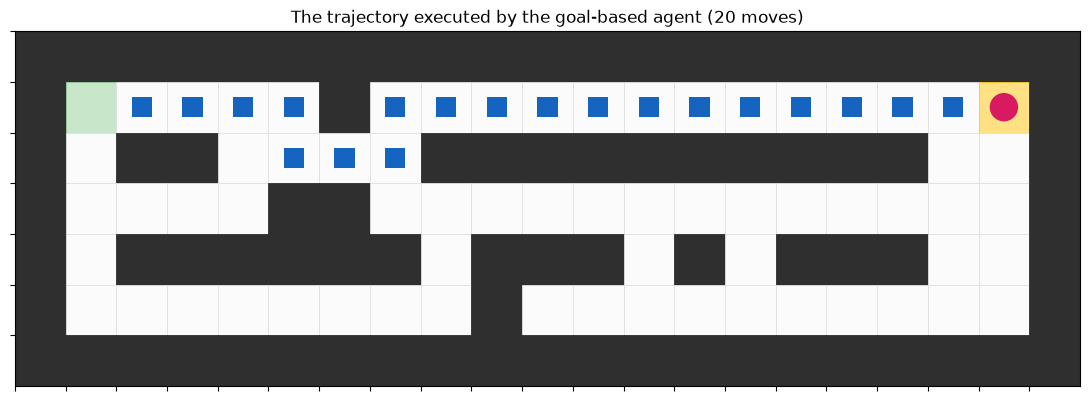

In [12]:
# Draw the trajectory the agent actually executed.

def draw_warehouse(grid, path=None, position=None, title=""):
    """Draw the warehouse, marking a path and the agent's final position."""
    marked = set(path or [])
    fig, ax = plt.subplots(figsize=(11, 5))
    for r, row in enumerate(grid):
        for c, ch in enumerate(row):
            if ch == "#":
                colour, edge = "#2f2f2f", "#2f2f2f"
            elif ch == "S":
                colour, edge = "#c8e6c9", "#9ccc9c"
            elif ch == "G":
                colour, edge = "#ffe082", "#ffca28"
            else:
                colour, edge = "#fbfbfb", "#e0e0e0"
            ax.add_patch(plt.Rectangle((c, r), 1, 1, facecolor=colour,
                                       edgecolor=edge, linewidth=0.6))
    for r, c in marked:
        ax.add_patch(plt.Rectangle((c + 0.3, r + 0.3), 0.4, 0.4,
                                   facecolor="#1565c0", zorder=3))
    if position is not None:
        ax.add_patch(plt.Circle((position[1] + 0.5, position[0] + 0.5), 0.28,
                                facecolor="#d81b60", zorder=4))
    ax.set_xlim(0, len(grid[0]))
    ax.set_ylim(len(grid), 0)
    ax.set_aspect("equal")
    ax.set_xticks(range(len(grid[0])))
    ax.set_yticks(range(len(grid)))
    ax.set_xticklabels([])
    ax.set_yticklabels([])
    ax.set_title(title)
    plt.tight_layout()
    return fig


trajectory = [cell for _, _, cell in outcome["trace"]]
draw_warehouse(WAREHOUSE, path=trajectory, position=agent.position,
               title="The trajectory executed by the goal-based agent (%d moves)" % outcome["steps"])
plt.show()

### The four questions of Task 3

**1. Did the LLM generate a working program on the first attempt?**

**No.** The draft failed every one of the five tests. It found the right path on the
warehouse, but reported its length as 21 instead of 20; it crashed with a
`TypeError` when the goal was unreachable; and it crashed again when the same map
was passed in twice, because it had overwritten the `S` marker the first time. The
program was *almost* right in a way that is much worse than being obviously wrong:
the output looked completely reasonable and the defects were in the interface rather
than in the visible behaviour.

**2. If not, how can you improve the prompt?**

By turning every implicit expectation into an explicit one. The three failures
correspond to three unstated requirements, so the improved prompt adds exactly those
three: *always return the same four keys, with `found` as a boolean and `path` and
`length` as `None` when there is no path, and never raise an exception*; *`length`
is the number of moves, one less than the number of cells*; and *do not modify the
grid you are given*. Two further sentences were added as a matter of good practice
rather than in response to a failure — a definition of what "expanded" counts, and
the requirement that two runs on the same map give the same answer. The prompt grew
by about a third, and the program went from failing every test to passing every
test.

**3. What search algorithm did the LLM choose?**

**A\* search with the Manhattan distance as the heuristic** — expand the state with
the smallest $f(n) = g(n) + h(n)$, where $g(n)$ is the number of moves taken so far
and $h(n)$ is the Manhattan distance from that cell to `G`.

**4. Why do you think the LLM selected this algorithm?**

Because it is the standard answer for "shortest path on a grid", and because the
prompt's four requirements match A\* exactly. The prompt asked for a *collision-free
path* — that rules out a local steering rule — and for the *path* rather than just
the arrival, which implies that path quality matters. A\* is the algorithm that
returns a shortest path on a grid while expanding far fewer states than an
uninformed search. The model chose it because the request was, in effect, a
description of A\*.

A second reason is worth recording: the model chose it *because it is the safest
thing to write*. A\* is the algorithm with the most examples in training data, it
has a well-understood correctness argument, and it is the one most likely to
produce a program that works. When an LLM is given a specification, the algorithm it
picks is usually the one that is hardest to criticise — which is useful, because it
means the interesting part of the work is not "which algorithm" but "is this program
actually correct".

## The "Think about it" question, measured

The question in Task 1 was: if the warehouse becomes twice as large, would the same
search strategy still be appropriate, and what additional difficulties arise?

The experiment below builds warehouses of the same character but growing size — a
solid outer wall, horizontal shelving runs with gaps, and vertical shelving blocks —
and runs the same two searches on each of them. Both searches are given exactly the
same map, so the only thing that differs is the size.

In [13]:
import random
import time


def generate_warehouse(rows, cols, seed):
    """Build a warehouse of a given size, in the style of the lab map.

    A solid outer wall, horizontal shelving runs with one gap each, a few
    vertical shelving blocks, and a corridor is carved from S to G so that the
    problem is always solvable.
    """
    rng = random.Random(seed)
    grid = [["."] * cols for _ in range(rows)]
    for r in range(rows):
        grid[r][0] = grid[r][cols - 1] = "#"
    for c in range(cols):
        grid[0][c] = grid[rows - 1][c] = "#"

    # horizontal shelving units
    for r in range(1, rows - 1):
        if rng.random() < 0.6:
            run = rng.randint(3, max(4, cols // 2))
            c0 = rng.randint(1, max(1, cols - 2 - run))
            gap = rng.randint(c0, min(cols - 2, c0 + run - 1))
            for c in range(c0, min(cols - 1, c0 + run)):
                grid[r][c] = "#"
            grid[r][gap] = "."

    # vertical shelving units
    for _ in range(rng.randint(2, 6)):
        r0 = rng.randint(1, max(1, rows - 2))
        c0 = rng.randint(1, max(1, cols - 2))
        h = rng.randint(1, max(1, rows // 3))
        w = rng.randint(1, max(1, cols // 6))
        for r in range(r0, min(rows - 1, r0 + h)):
            for c in range(c0, min(cols - 1, c0 + w)):
                grid[r][c] = "#"

    # carve a guaranteed corridor from S to G (a random staircase)
    r = 1
    for c in range(1, cols - 1):
        grid[r][c] = "."
        if rng.random() < 0.45 and r < rows - 2:
            grid[r + 1][c] = "."
            r += 1
    for rr in range(1, r + 1):
        grid[rr][cols - 2] = "."
    grid[1][1] = "S"
    grid[1][cols - 2] = "G"
    return ["".join(row) for row in grid]


SIZES = [(7, 21), (14, 42), (21, 63), (28, 84), (35, 105)]
SEEDS_PER_SIZE = 5

print("Each size is measured on %d different warehouses, because the exact" % SEEDS_PER_SIZE)
print("number of states A* expands depends on where the shelves happen to be.")
print("The table reports the mean; the range in brackets is the smallest and")
print("the largest value measured.")
print()
print("%-9s %-7s %-15s %-15s %-10s %-10s %-9s" %
      ("size", "free", "BFS expanded", "A* expanded", "BFS ms", "A* ms", "optimum"))
print("-" * 94)

scaling_rows = []
for rows, cols in SIZES:
    bfs_counts, astar_counts, free_counts, optima = [], [], [], []
    bfs_ms = astar_ms = 0.0

    for k in range(SEEDS_PER_SIZE):
        grid = generate_warehouse(rows, cols, seed=rows * 1000 + cols + k)
        free_counts.append(len(parse_grid(grid)[3]))

        t0 = time.perf_counter()
        result_bfs = bfs_reference(grid)
        t1 = time.perf_counter()
        result_astar = astar_v2(grid)
        t2 = time.perf_counter()

        bfs_counts.append(result_bfs["expanded"])
        astar_counts.append(result_astar["expanded"])
        optima.append(result_bfs["length"])
        bfs_ms += (t1 - t0) * 1000
        astar_ms += (t2 - t1) * 1000

    def mean(values):
        return sum(values) / len(values)

    row = {
        "size": "%dx%d" % (rows, cols),
        "free": int(round(mean(free_counts))),
        "bfs_expanded": int(round(mean(bfs_counts))),
        "astar_expanded": int(round(mean(astar_counts))),
        "bfs_range": (min(bfs_counts), max(bfs_counts)),
        "astar_range": (min(astar_counts), max(astar_counts)),
        "bfs_ms": bfs_ms / SEEDS_PER_SIZE,
        "astar_ms": astar_ms / SEEDS_PER_SIZE,
        "optimum": int(round(mean(optima))),
    }
    scaling_rows.append(row)

    print("%-9s %-7d %-15s %-15s %-10.2f %-10.2f %-9d" % (
        row["size"], row["free"],
        "%d [%d-%d]" % (row["bfs_expanded"], row["bfs_range"][0], row["bfs_range"][1]),
        "%d [%d-%d]" % (row["astar_expanded"], row["astar_range"][0], row["astar_range"][1]),
        row["bfs_ms"], row["astar_ms"], row["optimum"]))

print()
print("Both searches return the same optimal length on every map, so the")
print("comparison is fair: only the amount of work differs.")

Each size is measured on 5 different warehouses, because the exact
number of states A* expands depends on where the shelves happen to be.
The table reports the mean; the range in brackets is the smallest and
the largest value measured.

size      free    BFS expanded    A* expanded     BFS ms     A* ms      optimum  
----------------------------------------------------------------------------------------------
7x21      76      73 [66-77]      43 [19-58]      0.15       0.21       22       
14x42     371     325 [302-357]   57 [40-75]      0.55       0.33       41       
21x63     955     836 [782-883]   117 [61-269]    1.46       0.76       63       
28x84     1725    1462 [1420-1506] 123 [82-172]    2.41       0.95       83       
35x105    2748    2296 [2233-2409] 155 [103-236]   4.01       1.38       104      

Both searches return the same optimal length on every map, so the
comparison is fair: only the amount of work differs.


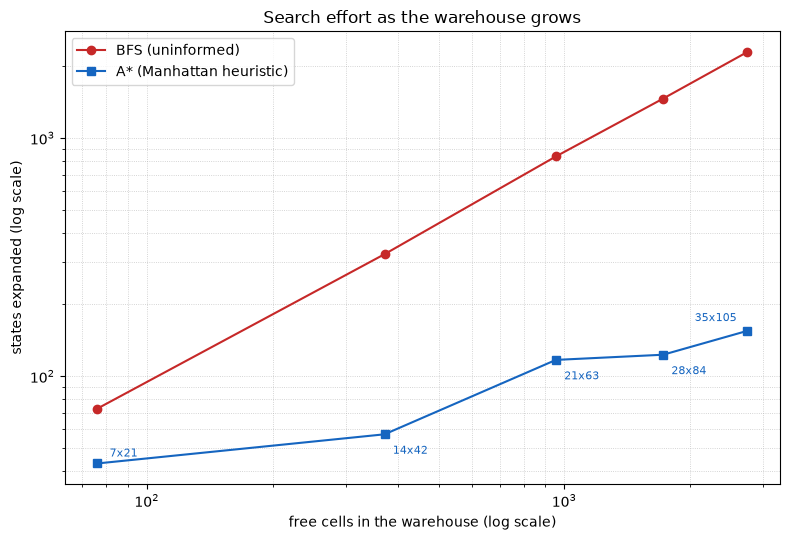

In [14]:
# How the two searches scale.

fig, ax = plt.subplots(figsize=(8, 5.5))
free_cells = [row["free"] for row in scaling_rows]
ax.plot(free_cells, [row["bfs_expanded"] for row in scaling_rows], "o-",
        color="#c62828", label="BFS (uninformed)")
ax.plot(free_cells, [row["astar_expanded"] for row in scaling_rows], "s-",
        color="#1565c0", label="A* (Manhattan heuristic)")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("free cells in the warehouse (log scale)")
ax.set_ylabel("states expanded (log scale)")
ax.set_title("Search effort as the warehouse grows")
ax.grid(True, which="both", linestyle=":", linewidth=0.6, alpha=0.7)
ax.legend()
for index, row in enumerate(scaling_rows):
    if index == 0:
        offset = (9, 5)
    elif index == len(scaling_rows) - 1:
        offset = (-38, 7)
    else:
        offset = (6, -14)
    ax.annotate(row["size"], (row["free"], row["astar_expanded"]),
                textcoords="offset points", xytext=offset, fontsize=8, color="#1565c0")
plt.tight_layout()
plt.show()

### What the measurement says

Each size in the table above is the mean over five different warehouses of that
size, because the number of states A\* expands depends on where the shelves happen
to be. The averages are what make the trend visible: BFS tracks the size of the
warehouse closely, while A\* barely moves.

**Would the same search strategy still be appropriate?** Yes for these sizes, and
the measurement says exactly *why*. On every map both searches return the same
optimal path length, so neither is wrong; the difference is entirely in the work
done. BFS expands almost every free cell in the warehouse, because it has to
exhaust the whole reachable region before it can be certain it has found the
shortest path. A\* expands a small fraction of it, and the fraction keeps shrinking
as the warehouse grows: on the $28 \times 84$ warehouses A\* expanded **123** states
on average where BFS expanded **1462**, a factor of **12**, and on the largest
warehouse the factor was **15** (155 states against 2296).

**What additional difficulties arise?**

1. **The state space grows faster than the map.** The number of free cells grows
   roughly quadratically with the linear size (76 → 371 → 955 → 1725 → 2748 in the
   table above), so the search space grows by a factor of about 4 for every doubling
   of the width and height. A search that must touch every state therefore becomes
   four times more expensive per doubling - and BFS's cost really does grow like
   that, while A\*'s grows much more slowly.
2. **Memory becomes the binding constraint.** BFS keeps every discovered but
   unexpanded state in the frontier at once. On the largest map here that is over a
   thousand states, and it grows linearly with the warehouse. For a warehouse
   hundreds of times larger, the frontier - not the CPU - is what stops the search,
   and the strategy has to change to a depth-first search with a cost bound (IDA\*),
   which uses $O(d)$ memory instead of $O(N)$.
3. **The heuristic gets weaker as the map grows.** Manhattan distance cannot see
   shelving units, so the longer the detour around them, the worse the estimate.
   On the lab's own map the estimate says 18 while the truth is 20; on a warehouse
   twice as large the detour can be twice as long and the estimate no longer
   describes the shape of the route at all. The gap between the estimate and the
   truth is what pulls A\* into the dead ends, and dead ends get deeper.
4. **A\* is not guaranteed to stay ahead.** The advantage of A\* here comes from the
   Manhattan estimate being *directionally* right - the goal really is to the right
   - not from it being accurate. If a warehouse is built so that the goal lies
   *behind* a wall of shelving units, the estimate becomes useless, A\* degenerates
   towards BFS, and the informed search buys nothing.

So the honest answer to "would the same strategy still be appropriate?" is: the
same *code* certainly still works and still returns the correct answer, but the same
*strategy* is only appropriate while the warehouse stays small enough that memory
is not the limit and the Manhattan estimate stays roughly aligned with the real
route. Past that point the algorithm has to be replaced, not merely re-run - and the
measurements above say the replacement is coming sooner than the doubling of the
map size would suggest.

## Evaluating LLM-assisted software engineering

The last learning objective of the lab is to "critically evaluate the strengths and
limitations of LLM-assisted software engineering". The evidence for that evaluation
is the exercise itself.

### What the LLM did well

- **It produced a complete, well-structured program in one attempt.** The draft
  parsed the ASCII map, built a heap-based frontier, computed $f = g + h$
  explicitly, reconstructed the path through parent pointers and reported the four
  fields the prompt asked for. All of that matched the Task 2 design, and none of
  it needed to be rewritten.
- **It chose a sensible algorithm.** A\* with Manhattan distance is the right
  choice for this problem, and it explained why in the comments.
- **It removed all the mechanical work.** The laborious part of the exercise -
  getting the bookkeeping of a priority-queue search right - was done in seconds.

### What the LLM got wrong

- **It filled in the gaps silently.** Every one of the three defects was a decision
  the model made without being told: what to return when there is no path, whether
  "length" means cells or moves, and whether the input may be modified. A human
  reviewer reading the draft quickly would also have missed the off-by-one, because
  the code reads correctly and the bug is in a single token.
- **Its output looked finished.** The failure mode is not an error message; it is
  a well-formatted report with one number in it that is wrong. Working output is
  not validated software.
- **The defects are of the kind that prose invites.** "Return the path" suggests
  returning the list of cells, and the length of that list is 21. The model wrote
  what the request said, and the request was ambiguous.

### What this means for the workflow

The design was the part that mattered. The lab puts Task 1 and Task 2 *before* the
model is used, and that ordering is the lesson: the LLM is a fast implementation of
a specification, and a weak substitute for writing one. Every defect above was
already latent in the Task 3 prompt, and every one of them was removed by writing
down what the prompt had left unsaid.

The rules that follow from this exercise are short:

1. **Specify the interface, not just the behaviour.** Keys, types, units, and what
   happens in the failure case.
2. **Test against an oracle that was not written by the model.** The breadth-first
   reference in this notebook is what turned "the program printed a path" into "the
   program printed a *shortest* path".
3. **Test the second run.** The mutation defect was invisible to every test that
   ran the program once.
4. **Never accept a plausible output as a correct program.** The draft's output was
   well-formed and wrong.
5. **Keep the human accountable.** The model wrote the code; the engineer wrote the
   specification and the tests, and the engineer is the one who signs the result.

## Summary of results

The table below is generated from the objects measured above, so every number in it
is the number that was actually observed.

In [15]:
# --- the summary table, computed from the measurements above ---------------
best_bfs = bfs_reference(WAREHOUSE)
best_astar = astar_v2(WAREHOUSE)

rows_summary = [
    ("The lab's warehouse",
     "A solution of **%d moves**, confirmed optimal by an independent BFS; the path "
     "is collision-free." % best_bfs["length"]),
    ("The reflex agent",
     "**Fails.** Given the same map and position it cycles in the bottom-right "
     "region and never reaches `G`."),
    ("Draft v1 (generated from the first prompt)",
     "**Fails %d of %d checks**: the length is off by one (%d instead of %d), a "
     "`TypeError` on an unreachable goal, and a `TypeError` on the second run."
     % (v1_total - v1_passed, v1_total, best_astar["length"] + 1, best_astar["length"])),
    ("Version 2 (generated from the improved prompt)",
     "**Passes %d of %d checks** - the same five tests, unchanged."
     % (v2_passed, v2_total)),
    ("BFS vs A* on the lab map",
     "Both return the same %d-move path; BFS expands **%d** states, A* expands **%d**."
     % (best_bfs["length"], best_bfs["expanded"], best_astar["expanded"])),
]
for row in scaling_rows:
    rows_summary.append((
        "Scaling: %s" % row["size"],
        "%d free cells; BFS expands **%d** states, A* expands **%d** - a factor of "
        "**%.1f** fewer." % (row["free"], row["bfs_expanded"], row["astar_expanded"],
                            row["bfs_expanded"] / max(1, row["astar_expanded"])),
    ))
rows_summary.append((
    "The executed trajectory",
    "%d moves, each one legal at the moment it was taken, ending on `G`." % outcome["steps"],
))

from IPython.display import Markdown, display


class MarkdownTable(Markdown):
    """Markdown that also falls back to its own source as plain text.

    Without this, a viewer that cannot render the markdown mime type shows
    '<IPython.core.display.Markdown object>' instead of the table.
    """

    def __repr__(self):
        return self.data


table = ["| Experiment | Result |", "|---|---|"]
table += ["| %s | %s |" % (name, result) for name, result in rows_summary]
display(MarkdownTable("\n".join(table)))

| Experiment | Result |
|---|---|
| The lab's warehouse | A solution of **20 moves**, confirmed optimal by an independent BFS; the path is collision-free. |
| The reflex agent | **Fails.** Given the same map and position it cycles in the bottom-right region and never reaches `G`. |
| Draft v1 (generated from the first prompt) | **Fails 6 of 9 checks**: the length is off by one (21 instead of 20), a `TypeError` on an unreachable goal, and a `TypeError` on the second run. |
| Version 2 (generated from the improved prompt) | **Passes 10 of 10 checks** - the same five tests, unchanged. |
| BFS vs A* on the lab map | Both return the same 20-move path; BFS expands **59** states, A* expands **23**. |
| Scaling: 7x21 | 76 free cells; BFS expands **73** states, A* expands **43** - a factor of **1.7** fewer. |
| Scaling: 14x42 | 371 free cells; BFS expands **325** states, A* expands **57** - a factor of **5.7** fewer. |
| Scaling: 21x63 | 955 free cells; BFS expands **836** states, A* expands **117** - a factor of **7.1** fewer. |
| Scaling: 28x84 | 1725 free cells; BFS expands **1462** states, A* expands **123** - a factor of **11.9** fewer. |
| Scaling: 35x105 | 2748 free cells; BFS expands **2296** states, A* expands **155** - a factor of **14.8** fewer. |
| The executed trajectory | 20 moves, each one legal at the moment it was taken, ending on `G`. |

## Final reflection

**Why is it important to formulate the problem before generating any code?** Because
the formulation is the only thing the code can be checked against. Without a
defined goal, a defined cost and a defined state, "the program returned a path" is
a sentence with no content in it: there is nothing to compare the path against and
no way to tell a correct answer from a wrong one. In this lab the formulation also
settled the engineering. Because every move costs 1, the number of moves *is* the
cost, so a single number measures both the quality of the answer and — through the
number of expanded states — the effort spent finding it.

**What is the difference between a goal-based agent and a reflex agent, in this
problem?** The reflex agent has no representation of the objective: it reacts to the
cell it is in, and the experiment shows it cycling forever in a region it has no
reason to leave. The goal-based agent keeps the goal in its internal state, uses it
to *deliberate* over the state space, and thereby discovers that the corridor it is
standing in is a dead end — something no amount of reacting can reveal. The goal is
not a wish; it is a variable in the agent's state that changes what it does.

**What did the LLM contribute, and what did it not?** It contributed speed and
structure: the correct algorithm, the right data structures, and a complete
implementation in a single attempt. It did not contribute the specification, and the
three defects it produced were all gaps in that specification. The model's output
was never the scarce ingredient; the scarce ingredient was knowing what to ask for
and what to check.

**What is the single most important habit this lab builds?** Writing the test
before trusting the output. The draft's output was well-formatted and plausible;
only the assertions caught it. The general lesson generalises well beyond this
laboratory: **an LLM gives you code, not correctness, and the difference between
the two is exactly the work you were going to have to do anyway.**